## Test Ticker Samples

In [1]:


%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.sanos.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree
%aimport quantdata.widb.options_filter
%aimport quantdata.widb.timeseries

from datetime import date
from quantdata.widb.timeseries import build_time_series, TimeSeriesDefinition, ExpiryFilter, RawDayFilter, OptionsFilter, DateRange, PoolConfig, table_of_time_series, MkArbFree
from quantdata.biz_calendar import next_business_day
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context
from IPython.display import display

def test():
    ticker = "SPX"
    time_series_def = TimeSeriesDefinition(
        raw_day_filter = RawDayFilter(),
        expiry_filter = ExpiryFilter(),
        mk_arb_free = MkArbFree(),
        options_filter = OptionsFilter()
    )
    date_range = DateRange(start=date(2015, 4, 1), end=date(2025, 7, 1))
    pool_config = PoolConfig(num_workers=4, threading=False)
    verbose = Context.all

    samples = build_time_series(ticker, date_range, include_fields=None, exclude_fields=None, time_series_def=time_series_def, pool_config=pool_config, verbose=verbose, override_cache_mode="on" )
    return samples

samples = test()
verbose = Context.all
verbose.write(str(table_of_time_series(samples)))
print("/done")

00: Aggregating arbitrage-free data for ticker SPX for 2556 business days from 2015-04-01 to 2025-07-01 excluding half days:
01:   Options filter: nopt=1000,bdte=756,nmsat=(-5.0, 2.0),lvolu=1.0,loi=1.0,rmam=False,vegaSV=0.001,mxpp=10
01:   MkArbFree config: surface,mhs=0.0001,mw=0.10,mik=5,mdn=0.0001,dC=0.001,dps=0.0001
01:   Raw Day filter: bid=0.011
01:   Expiry filter: nat,eth=10,bth=4,mps=1e-06,miv=0.01,xiv=5.0
01:   Pool config: workers 4p
01:   Requested fields: ask_vol, bdte, bid_vol, call_ask, call_bid, call_opt_id, date, df, expiry, expiry_id, fit1_vol, fitX_vol, fwd, fwd_ref, is_am, is_american, is_valid, log_open_interest, log_volume, mask_arb_free, mkt_call_ask, mkt_call_bid, mkt_call_log_open_interest, mkt_call_log_volume, mkt_put_ask, mkt_put_bid, mkt_put_log_open_interest, mkt_put_log_volume, nms, nms_atm, pure_ask_delta, pure_ask_dk, pure_ask_gamma, pure_ask_price, pure_ask_theta, pure_ask_vega, pure_bid_delta, pure_bid_dk, pure_bid_gamma, pure_bid_price, pure_bid_theta

/mnt/c/Users/hans/OneDrive/Python3/quant_data/quantdata/widb/timeseries.py:263: UserWarning: Warning: SPX 2015-08-21: no data after filtering for this day. This date will be skipped in the time series.


00: Read the generated arbitrage-free enriched data for SPX in the main process; this took 52s. Maximum number of options is 1000.00: Generating time series for 2555 business days and at most 1000 options per day for ticker SPX... done; this took 0.8s.
02:     +----------------------------+--------------+----------------+-------------+-----------+-----------+-----------+-----------+
02:     |           Field            |    Shape     |     Dtype      |     Size    |    Mean   |    Std    |    Min    |    Max    |
02:     +----------------------------+--------------+----------------+-------------+-----------+-----------+-----------+-----------+
02:     |           dates            |   (2555,)    |      date      |             |           |           |           |           |
02:     |          is_valid          | (2555, 1000) |      bool      |  2495.12KB  |   0.9544  |   0.2086  |     0     |     1     |
02:     |           time_y           |  (2555, 1)   |    float32     | 10220 bytes

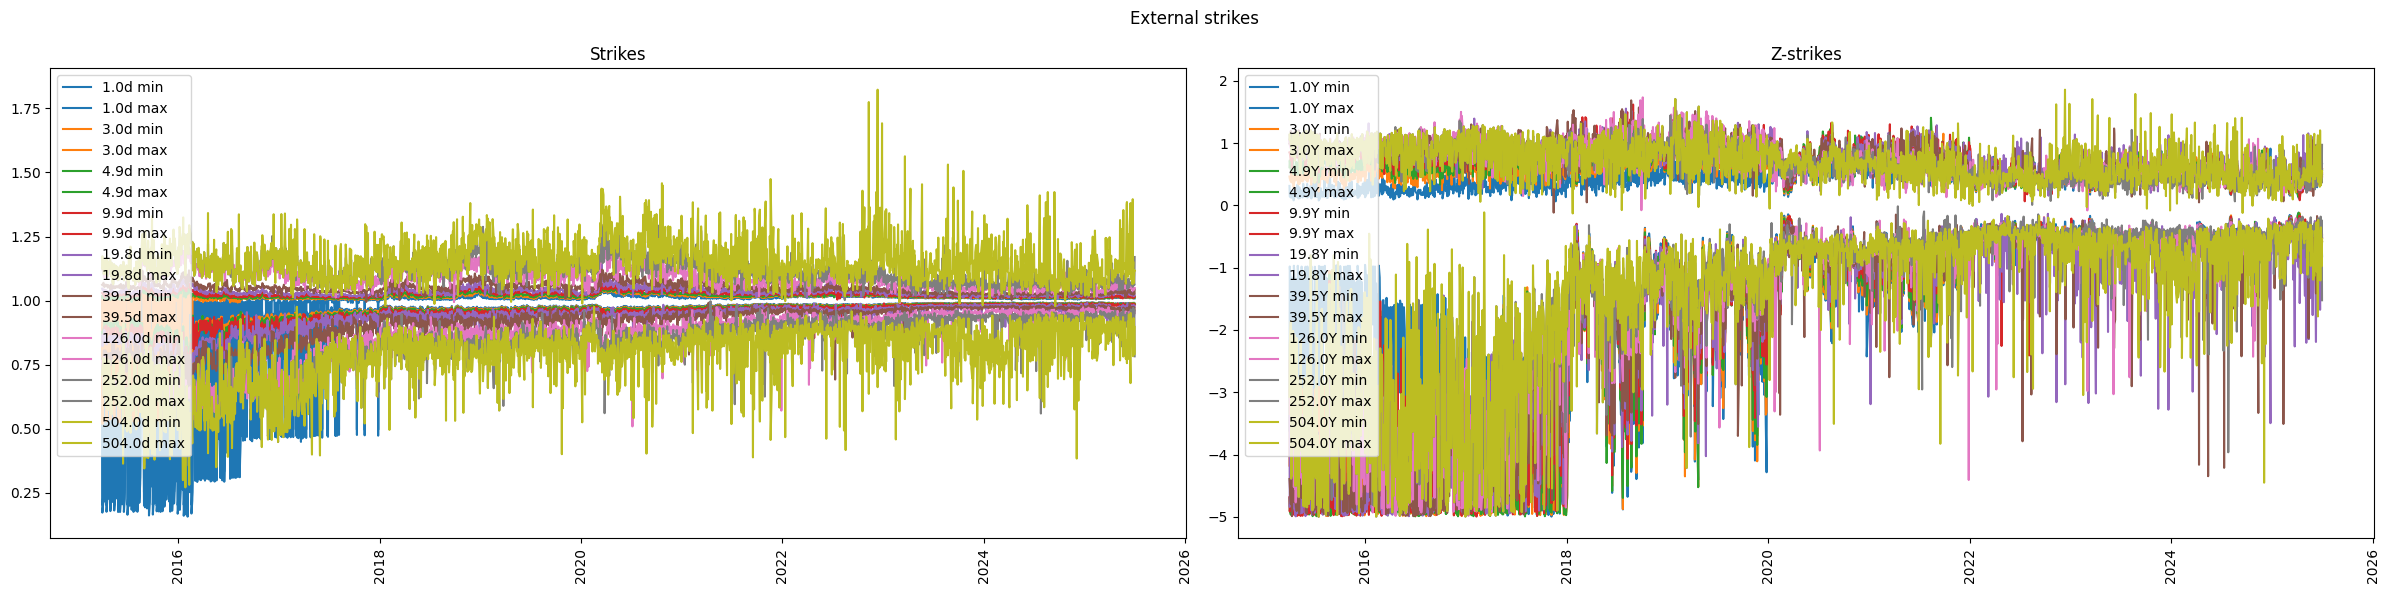

In [17]:
import numpy as np
from cdxcore.dynaplot import figure, colors_tableau

DEFAULT_EXPIRIES = np.array([1./255., 3./255., 5./255., 10./255., 20./255., 40./255.,0.5,1.,2.], dtype=np.float64)

def z_strike(samples):

    ks  = np.zeros((len(samples['dates']), len(DEFAULT_EXPIRIES), 2), dtype=np.float64)
    nms = np.zeros((len(samples['dates']), len(DEFAULT_EXPIRIES), 2), dtype=np.float64)

    for idd, d in enumerate(samples['dates']):

        src_exp  = samples['tte_y'][idd,:]
        expiries = np.unique(src_exp)
        strikes  = samples['pure_strike'][idd,:]
        nms_atm  = samples['nms_atm'][idd,:]
        masks    = [ expiry == src_exp for expiry in expiries ]
        strikes  = [ strikes[mask] for mask in masks ]
        nms_atm  = [ nms_atm[mask] for mask in masks ]

        lo_k     = np.array([ np.min(strikes[t]) for t in range(len(expiries)) ])
        hi_k     = np.array([ np.max(strikes[t]) for t in range(len(expiries)) ])
        lo_z     = np.array([ np.min(nms_atm[t]) for t in range(len(expiries)) ])
        hi_z     = np.array([ np.max(nms_atm[t]) for t in range(len(expiries)) ])

        ks[idd,:,0]    = np.interp( DEFAULT_EXPIRIES, expiries, lo_k )
        ks[idd,:,1]    = np.interp( DEFAULT_EXPIRIES, expiries, hi_k )
        nms[idd,:,0]   = np.interp( DEFAULT_EXPIRIES, expiries, lo_z )
        nms[idd,:,1]   = np.interp( DEFAULT_EXPIRIES, expiries, hi_z )

    with figure("External strikes", row_size=6, col_size=12, columns=2) as fig:
        axK, axZ = fig.add_subplots("Strikes", "Z-strikes")
        colors   = colors_tableau()

        for j, expiry in enumerate(DEFAULT_EXPIRIES):
            expiry = expiry * 252.
            color  = next(colors)
            axK.plot( samples['dates'], ks[:,j,0], label=f"{expiry:.1f}d min", color=color )
            axK.plot( samples['dates'], ks[:,j,1], label=f"{expiry:.1f}d max", color=color )
            axZ.plot( samples['dates'], nms[:,j,0], label=f"{expiry:.1f}Y min", color=color )
            axZ.plot( samples['dates'], nms[:,j,1], label=f"{expiry:.1f}Y max", color=color )
        axK.legend()
        axZ.legend()
        axK.tick_params(axis="x", labelrotation=90)   # vertical
        axZ.tick_params(axis="x", labelrotation=90)   # vertical

z_strike(samples)
